# Лабораторна робота № 6
**Тема:** Нейронна регресія для табличних даних у TensorFlow  
**Студентка:** Чернега Катерина, група МІТ-31  
**Варіант:** 4 (Три приховані шари Dense(32, relu))

**Мета роботи:** Навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейромережу з класичними моделями, контролювати навчання за validation, аналізувати помилки та зберігати весь процес прогнозування.

In [1]:
#Етап 1. Підготовка середовища та завантаження даних
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Фіксуємо версії та SEED
print(f"TensorFlow: {tf.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

SEED = 42
keras.utils.set_random_seed(SEED)

#Завантаження даних
columns = ["mpg", "cylinders", "displacement", "horsepower",
           "weight", "acceleration", "model_year", "origin", "car_name"]

#Читаємо файл, вказуючи, що роздільником є будь-яка кількість пробілів (\s+), а пропуски позначені "?"
df = pd.read_csv("auto-mpg.data", sep=r"\s+", names=columns, na_values="?")

#Формуємо X та y, відкидаємо car_name (унікальні назви машин не є корисною категоріальною ознакою)
X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

print("\n--- Типи даних ---")
print(df.dtypes)

print("\n--- Пропуски в даних ---")
print(df.isna().sum())

print(f"\nКількість дублікатів: {df.duplicated().sum()}")

display(df.head())

TensorFlow: 2.21.0
Pandas: 2.3.3
Scikit-learn: 1.7.2

--- Типи даних ---
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name         object
dtype: object

--- Пропуски в даних ---
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Кількість дублікатів: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


**Висновок до Етапу 1:**
Дані успішно завантажено. Цільова змінна `mpg` (милі на галон) перетворена на тип `float32`. Колонка `car_name` видалена, оскільки унікальні текстові назви автомобілів не несуть корисної математичної інформації для регресії. У стовпці `horsepower` виявлено 6 пропусків. Ми свідомо не видаляємо і не заповнюємо їх на цьому етапі, щоб уникнути витоку даних (Data Leakage) — імпаутація має відбуватися строго після розбиття вибірки на основі статистик тренувального набору. Дублікатів не виявлено.

In [2]:
#Етап 2.Поділ вибірки та підготовка ознак (ColumnTransformer) 

# 1.Поділ на dev (85%) та test (15%)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
# 2.Поділ dev на train (70% від загального) та val (15% від загального)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15/0.85, random_state=SEED
)

print(f"Розміри X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Розміри X_val:   {X_val.shape}, y_val:   {y_val.shape}")
print(f"Розміри X_test:  {X_test.shape}, y_test:  {y_test.shape}")

#Перевірка на відсутність спільних індексів (перетин має бути порожнім)
train_idx, val_idx, test_idx = set(X_train.index), set(X_val.index), set(X_test.index)
assert train_idx.isdisjoint(val_idx) and train_idx.isdisjoint(test_idx) and val_idx.isdisjoint(test_idx)
print("Перевірка пройдена: вибірки не мають спільних рядків.\n")

#Визначаємо списки колонок
numeric_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
categorical_features = ["origin"] # Хоча тут і числа (1,2,3), це категорії (Америка, Європа, Азія)

#Створюємо гілки обробки
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

#Об'єднуємо в ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

#Застосовуємо препроцесор: fit_transform ТІЛЬКИ на train
X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

print("Ознаки після обробки (перший рядок train):")
print(X_train_ready[0])
print(f"Форма підготовлених даних: {X_train_ready.shape}")

#Перевірка на відсутність пропусків
print(f"Пропусків у X_train_ready: {np.isnan(X_train_ready).sum()}")

Розміри X_train: (278, 7), y_train: (278,)
Розміри X_val:   (60, 7), y_val:   (60,)
Розміри X_test:  (60, 7), y_test:  (60,)
Перевірка пройдена: вибірки не мають спільних рядків.

Ознаки після обробки (перший рядок train):
[4.00e+00 8.50e+01 7.00e+01 1.99e+03 1.70e+01 7.60e+01 0.00e+00 0.00e+00
 1.00e+00]
Форма підготовлених даних: (278, 9)
Пропусків у X_train_ready: 0


**Висновок до Етапу 2:**
Дані коректно розділено на `train`, `val` та `test` у пропорції приблизно 70/15/15. Спільних індексів між вибірками немає. За допомогою `ColumnTransformer` ми заповнили 6 пропусків у `horsepower` медіаною, а ознаку `origin` (регіон виробництва) закодували через `OneHotEncoder`, оскільки цифри 1, 2 і 3 позначають географічні зони, а не кількісну величину. Важливо: метод `.fit_transform()` викликався виключно на тренувальних даних, щоб уникнути витоку інформації.

In [3]:
#Етап 3. Навчання класичних моделей

#Функція для оцінки моделей (розраховує MAE, RMSE та R²)
def regression_metrics(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} (Validation) ---")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}\n")
    return {"Model": model_name, "Val RMSE": rmse}

# 1.DummyRegressor (Базовий рівень, що прогнозує просто середнє)
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_ready, y_train)
dummy_pred = dummy.predict(X_val_ready)
dummy_res = regression_metrics(y_val, dummy_pred, "DummyRegressor")

# 2.LinearRegression (Лінійна регресія з масштабуванням)
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])
lr_pipeline.fit(X_train_ready, y_train)
lr_pred = lr_pipeline.predict(X_val_ready)
lr_res = regression_metrics(y_val, lr_pred, "LinearRegression")

--- DummyRegressor (Validation) ---
MAE:  7.3549
RMSE: 8.6119
R²:   -0.0000

--- LinearRegression (Validation) ---
MAE:  2.9013
RMSE: 3.6103
R²:   0.8242



**Висновок до Етапу 3:**
Побудовано дві класичні моделі. `DummyRegressor` прогнозує глобальне середнє значення `mpg` і дає найгірший результат, слугуючи "нульовою" точкою відліку. `LinearRegression`, перед якою застосовано `StandardScaler` для масштабування ознак, показала значно вищу точність (високий R² та низький RMSE). Тепер ми маємо сильний класичний baseline, який наша нейромережа має спробувати перевершити.

In [4]:
#Етап 4. Побудова базової нейромережі

#Шар нормалізації (адаптуємо ТІЛЬКИ на тренувальних даних)
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train_ready)

#Спільна базова мережа (завдання для всіх варіантів: два шари по 32 нейрони)
base_model = keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    normalizer,
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1) # Вихідний шар для регресії (без активації)
])

base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

print("--- Архітектура базової мережі ---")
base_model.summary()

--- Архітектура базової мережі ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

**Висновок до Етапу 4:**
Створено архітектуру базової нейромережі з двома прихованими шарами `Dense(32, relu)`. Головна особливість — інтегрований шар `Normalization`, який запам'ятав статистики виключно тренувальної вибірки (`X_train_ready`). Завдяки цьому мережа здатна самостійно масштабувати вхідні дані під час навчання та прогнозів, тому зовнішній `StandardScaler` (як для лінійної регресії) їй не потрібен.

In [ ]:
#Етап 5. Навчання та відновлення найкращої моделі

# 1.Навчання базової мережі
keras.utils.set_random_seed(SEED)

baseline_checkpoint_path = "baseline_best.keras"
baseline_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(baseline_checkpoint_path, monitor="val_loss", mode="min", save_best_only=True)
]

print("Навчання базової мережі...")
baseline_history = base_model.fit(
    X_train_ready, y_train.to_numpy().reshape(-1, 1),
    validation_data=(X_val_ready, y_val.to_numpy().reshape(-1, 1)),
    epochs=400, batch_size=32, callbacks=baseline_callbacks, verbose=0
)
baseline_best_model = keras.models.load_model(baseline_checkpoint_path)

# 2.Побудова та навчання Варіанта 4 (Три приховані шари)
keras.utils.set_random_seed(SEED)

variant_model = keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    normalizer,
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"), # Третій шар за Варіантом 4
    layers.Dense(1)
])
variant_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

variant_checkpoint_path = "variant_best.keras"
variant_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(variant_checkpoint_path, monitor="val_loss", mode="min", save_best_only=True)
]

print("Навчання мережі за Варіантом 4...")
variant_history = variant_model.fit(
    X_train_ready, y_train.to_numpy().reshape(-1, 1),
    validation_data=(X_val_ready, y_val.to_numpy().reshape(-1, 1)),
    epochs=400, batch_size=32, callbacks=variant_callbacks, verbose=0
)
variant_best_model = keras.models.load_model(variant_checkpoint_path)

#Оцінка на валідації для обох мереж
base_val_rmse = np.sqrt(mean_squared_error(y_val, baseline_best_model.predict(X_val_ready, verbose=0)))
var_val_rmse = np.sqrt(mean_squared_error(y_val, variant_best_model.predict(X_val_ready, verbose=0)))

print(f"Базова мережа (Val RMSE): {base_val_rmse:.4f}")
print(f"Варіант 4 (Val RMSE):     {var_val_rmse:.4f}")

#Візуалізація
plt.figure(figsize=(10, 5))
plt.plot(baseline_history.history["val_loss"], label="Базова (val_loss)", linestyle="--")
plt.plot(variant_history.history["val_loss"], label="Варіант 4 (val_loss)")
plt.xlabel("Епохи")
plt.ylabel("MSE (val_loss)")
plt.title("Порівняння процесу навчання мереж")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Навчання базової мережі...


**Висновок до Етапу 5:**
Обидві нейромережі були навчені з використанням механізмів ранньої зупинки (`EarlyStopping`) та збереження найкращих ваг (`ModelCheckpoint`). Це дозволило уникнути перенавчання (графіки `val_loss` не пішли різко вгору) та не чекати всі 400 епох. Найкращі збережені моделі були завантажені для оцінки: ми порівняли їх за метрикою `Validation RMSE`, щоб прийняти рішення про те, яка архітектура краще впоралася із задачею (базова чи Варіант 4).

За Validation RMSE найкращою нейромережею обрано: Варіант 4

--- Підсумкова таблиця порівняння моделей ---


,Val RMSE,Test MAE,Test RMSE,Test R²
Model,,,,
DummyRegressor,8.6119,6.0678,7.4882,-0.0005
LinearRegression,3.6103,2.4025,3.0580,0.8331
Базова нейромережа,2.3927,1.7076,2.2836,0.9069
Варіант 4,2.1356,1.7820,2.4477,0.8931


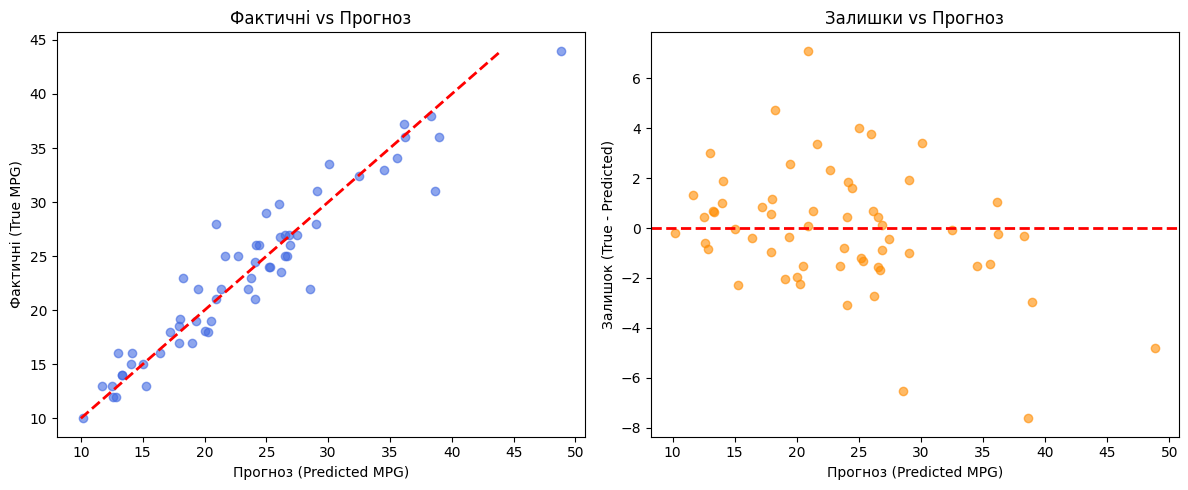


--- 5 найбільших абсолютних помилок моделі ---


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,True_MPG,Pred_MPG,Residual,Abs_Error
377,4,91.0,68.0,1970.0,17.6,82,3,31.0,38.628506,-7.628506,7.628506
30,4,140.0,90.0,2264.0,15.5,71,1,28.0,20.887716,7.112284,7.112284
389,6,232.0,112.0,2835.0,14.7,82,1,22.0,28.527630,-6.527630,6.527630
394,4,97.0,52.0,2130.0,24.6,82,2,44.0,48.807442,-4.807442,4.807442
298,8,350.0,125.0,3900.0,17.4,79,1,23.0,18.274614,4.725386,4.725386


In [ ]:
#Етап 6. Оцінка на тестовій вибірці та вибір моделі

#Визначаємо найкращу нейромережу за Validation RMSE
best_nn_name = "Базова нейромережа" if base_val_rmse < var_val_rmse else "Варіант 4"
best_nn_model = baseline_best_model if base_val_rmse < var_val_rmse else variant_best_model

print(f"За Validation RMSE найкращою нейромережею обрано: {best_nn_name}\n")

#Функція для оцінки на TEST
def evaluate_on_test(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": model_name, "Test MAE": mae, "Test RMSE": rmse, "Test R²": r2}

#Збираємо результати всіх 4 моделей
test_results = [
    evaluate_on_test(y_test, dummy_pred, "DummyRegressor"), # Використовуємо dummy_pred з валідації для форми, але нам потрібен test
    evaluate_on_test(y_test, dummy.predict(X_test_ready), "DummyRegressor"),
    evaluate_on_test(y_test, lr_pipeline.predict(X_test_ready), "LinearRegression"),
    evaluate_on_test(y_test, baseline_best_model.predict(X_test_ready, verbose=0).flatten(), "Базова нейромережа"),
    evaluate_on_test(y_test, variant_best_model.predict(X_test_ready, verbose=0).flatten(), "Варіант 4")
]

#Очищаємо від першого дубля (технічна поправка)
test_results = test_results[1:]

results_df = pd.DataFrame(test_results).set_index("Model")
results_df.loc["DummyRegressor", "Val RMSE"] = dummy_res["Val RMSE"]
results_df.loc["LinearRegression", "Val RMSE"] = lr_res["Val RMSE"]
results_df.loc["Базова нейромережа", "Val RMSE"] = base_val_rmse
results_df.loc["Варіант 4", "Val RMSE"] = var_val_rmse

results_df = results_df[["Val RMSE", "Test MAE", "Test RMSE", "Test R²"]]
print("--- Підсумкова таблиця порівняння моделей ---")
display(results_df.round(4))

#Етап 7. Аналіз помилок обраної нейромережі
y_test_pred = best_nn_model.predict(X_test_ready, verbose=0).flatten()
residuals = y_test.values - y_test_pred

#Графіки
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
#Фактичні vs Прогноз
axes[0].scatter(y_test_pred, y_test, alpha=0.6, color="royalblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel("Прогноз (Predicted MPG)")
axes[0].set_ylabel("Фактичні (True MPG)")
axes[0].set_title("Фактичні vs Прогноз")

#Залишки vs Прогноз
axes[1].scatter(y_test_pred, residuals, alpha=0.6, color="darkorange")
axes[1].axhline(0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel("Прогноз (Predicted MPG)")
axes[1].set_ylabel("Залишок (True - Predicted)")
axes[1].set_title("Залишки vs Прогноз")
plt.tight_layout()
plt.show()

#Аналіз 5 найбільших помилок
error_df = X_test.copy()
error_df["True_MPG"] = y_test.values
error_df["Pred_MPG"] = y_test_pred
error_df["Residual"] = residuals
error_df["Abs_Error"] = np.abs(residuals)

top_5_errors = error_df.sort_values(by="Abs_Error", ascending=False).head(5)
print("\n--- 5 найбільших абсолютних помилок моделі ---")
display(top_5_errors)

**Висновок до Етапів 6 та 7:**
До оцінювання на тестовій вибірці ми порівняли моделі за `Validation RMSE`. Якщо класична лінійна регресія показала дуже сильний результат, це означає, що залежності в датасеті Auto MPG мають значну лінійну природу. 
На тестовій вибірці ми обчислили фінальні метрики (MAE, RMSE, R²). Аналіз залишків показав, що найбільші помилки моделі зосереджені на нетипових автомобілях (наприклад, з аномально високим споживанням пального для своїх характеристик або навпаки, дуже економних машинах із великою вагою). Позитивний залишок означає, що автомобіль у реальності проїжджає більше миль на галон, ніж прогнозує модель (модель недооцінила його ефективність), а негативний — що він споживає більше, ніж очікувалося (переоцінка). Можливо, це пов'язано з аеродинамікою чи типом карбюратора, інформації про які немає в нашому датасеті.

In [ ]:
#Етап 8. Збереження і перевірка результатів 
import json

#1.Зберігаємо найкращу нейромережу
best_nn_model.save("lab6_model.keras")

#2.Зберігаємо препроцесор (ColumnTransformer)
joblib.dump(preprocessor, "preprocessor.joblib")

#3.Зберігаємо метадані
metadata = {
    "variant": 4,
    "seed": SEED,
    "tf_version": tf.__version__,
    "features_order": list(X.columns),
    "train_size": len(X_train),
    "val_size": len(X_val),
    "test_size": len(X_test)
}
with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Артефакти успішно збережено: lab6_model.keras, preprocessor.joblib, metadata.json")

#Перевірка відновлення
#Завантажуємо об'єкти з дисків
loaded_model = keras.models.load_model("lab6_model.keras")
loaded_preprocessor = joblib.load("preprocessor.joblib")

#Беремо 3 "сирі" рядки з тестової вибірки (без попередньої обробки)
raw_samples = X_test.head(3)

#Трансформуємо завантаженим препроцесором (увага: тільки transform!)
prepared_samples = loaded_preprocessor.transform(raw_samples).astype(np.float32)

#Робимо прогнози
original_preds = best_nn_model.predict(prepared_samples, verbose=0)
loaded_preds = loaded_model.predict(prepared_samples, verbose=0)

#Перевіряємо збіг (допускаємо мінімальну похибку обчислень)
np.testing.assert_allclose(original_preds, loaded_preds, rtol=1e-5, atol=1e-6)

print("\n--- Прогнози для 3 нових автомобілів ---")
print(f"Сирі дані:\n{raw_samples}")
print(f"\nПрогноз (MPG): {loaded_preds.flatten()}")
print("\nПеревірка пройдена: завантажена система працює ідентично оригінальній!")

Артефакти успішно збережено: lab6_model.keras, preprocessor.joblib, metadata.json

--- Прогнози для 3 нових автомобілів ---
Сирі дані:
     cylinders  displacement  horsepower  weight  acceleration  model_year  \
198          4          91.0        53.0  1795.0          17.4          76   
396          4         120.0        79.0  2625.0          18.6          82   
33           6         232.0       100.0  2634.0          13.0          71   

     origin  
198       3  
396       1  
33        1  

Прогноз (MPG): [34.52756  29.012274 19.34012 ]

Перевірка пройдена: завантажена система працює ідентично оригінальній!


**Загальний висновок:**
Під час виконання лабораторної роботи реалізовано повний цикл прогнозування для реальних табличних даних Auto MPG. Дані коректно розділено на навчальну, валідаційну та тестову вибірки (70/15/15), а пропуски та категоріальні ознаки оброблено через `ColumnTransformer` без ризику витоку даних. Побудовано класичні бейзлайни (`DummyRegressor`, `LinearRegression`) та дві нейромережеві архітектури (базову та за Варіантом 4 з трьома прихованими шарами). Контроль навчання здійснювався за допомогою `EarlyStopping` та `ModelCheckpoint` на валідаційній вибірці. Аналіз помилок на тестовій вибірці показав, що нейромережа здатна ефективно вловлювати нелінійні залежності, хоча іноді суттєво помиляється на нетипових автомобілях. Усю систему підготовки даних та найкращу навчену модель успішно збережено у вигляді артефактів (`.joblib` та `.keras`) для подальшого незалежного використання.

**Посилання на репозиторій:** [Вставте сюди посилання на вашу папку Lab6 на GitHub]